In [1]:
import pandas as pd
from pathlib import Path

def load_mrna_file(file_id, file_name, base="data/raw"):
    path = Path(base) / file_id / file_name
    df = pd.read_csv(path, sep="\t", skiprows=1)  # skip the "# gene-model" comment line
    df = df[df["gene_id"].str.startswith("ENSG")]  # drop the 4 summary stat rows
    df = df.set_index("gene_id")
    return df["tpm_unstranded"]

def load_mirna_file(file_id, file_name, base="data/raw"):
    path = Path(base) / file_id / file_name
    df = pd.read_csv(path, sep="\t")
    df = df.set_index("miRNA_ID")
    return df["reads_per_million_miRNA_mapped"]

In [ ]:

# find one real mRNA file and one real miRNA file
mrna_path = next(Path("data/raw").glob("*/*.rna_seq.augmented_star_gene_counts.tsv"))
mrna_file_id = mrna_path.parent.name
mrna_file_name = mrna_path.name
print("mRNA file:", mrna_file_id, mrna_file_name)

mirna_path = next(Path("data/raw").glob("*/*.mirnas.quantification.txt"))
mirna_file_id = mirna_path.parent.name
mirna_file_name = mirna_path.name
print("miRNA file:", mirna_file_id, mirna_file_name)

# test the mRNA loader
mrna_series = load_mrna_file(mrna_file_id, mrna_file_name)
print("\n--- mRNA test ---")
print(mrna_series.head())
print("Number of genes:", len(mrna_series))
print("dtype:", mrna_series.dtype)

# test the miRNA loader
mirna_series = load_mirna_file(mirna_file_id, mirna_file_name)
print("\n--- miRNA test ---")
print(mirna_series.head())
print("Number of miRNAs:", len(mirna_series))
print("dtype:", mirna_series.dtype)

mRNA file: 2aa3a845-cce2-4fe2-92f7-1fece9e619d5 3fab2674-2e00-4748-9d33-9e52631cebfd.rna_seq.augmented_star_gene_counts.tsv
miRNA file: d8e18a38-0e22-4c3e-882e-2036af42a78a a3a9999c-52e6-4c7f-a39e-575d73177f10.mirbase21.mirnas.quantification.txt

--- mRNA test ---
gene_id
ENSG00000000003.15     18.9429
ENSG00000000005.6       0.7690
ENSG00000000419.13    107.8981
ENSG00000000457.14     11.3049
ENSG00000000460.17     13.3155
Name: tpm_unstranded, dtype: float64
Number of genes: 60660
dtype: float64

--- miRNA test ---
miRNA_ID
hsa-let-7a-1    7889.027302
hsa-let-7a-2    7703.268940
hsa-let-7a-3    7950.132027
hsa-let-7b      6782.624423
hsa-let-7c      1008.635320
Name: reads_per_million_miRNA_mapped, dtype: float64
Number of miRNAs: 1881
dtype: float64


In [3]:
sheet = pd.read_csv("gdc_sample_sheet.2026-08-17.tsv", sep="\t")

# check the real values before filtering
print(sheet["Tissue Type"].value_counts())
print(sheet["Tumor Descriptor"].value_counts())
print(sheet["Data Type"].value_counts())

Tissue Type
Tumor     2221
Normal     217
Name: count, dtype: int64
Tumor Descriptor
Primary           2207
Not Applicable     217
Metastatic          14
Name: count, dtype: int64
Data Type
Gene Expression Quantification     1231
miRNA Expression Quantification    1207
Name: count, dtype: int64


In [4]:
tumor_primary = sheet[
    (sheet["Tissue Type"] == "Tumor") &
    (sheet["Tumor Descriptor"] == "Primary")
]

mrna_sheet = tumor_primary[tumor_primary["Data Type"] == "Gene Expression Quantification"]
mirna_sheet = tumor_primary[tumor_primary["Data Type"] == "miRNA Expression Quantification"]

print(len(mrna_sheet), len(mirna_sheet))

1111 1096


In [5]:
matched_ids = set(mrna_sheet["Sample ID"]) & set(mirna_sheet["Sample ID"])
print("Matched samples:", len(matched_ids))

Matched samples: 1087


In [ ]:
from tqdm import tqdm  #dropdown progress bar for loops

# # restrict each sheet to just the matched sample IDs, and drop duplicates
# # (keep only one file per sample ID, in case of rare duplicates)
mrna_sheet_matched = mrna_sheet[mrna_sheet["Sample ID"].isin(matched_ids)].drop_duplicates("Sample ID")
mirna_sheet_matched = mirna_sheet[mirna_sheet["Sample ID"].isin(matched_ids)].drop_duplicates("Sample ID")

print(len(mrna_sheet_matched), len(mirna_sheet_matched))

1087 1087


In [9]:
mrna_rows = {}
for _, row in tqdm(mrna_sheet_matched.iterrows(), total=len(mrna_sheet_matched)):
    mrna_rows[row["Sample ID"]] = load_mrna_file(row["File ID"], row["File Name"])

mrna_matrix = pd.DataFrame(mrna_rows).T
print(mrna_matrix.shape)

  0%|          | 0/1087 [00:00<?, ?it/s]

100%|██████████| 1087/1087 [01:35<00:00, 11.40it/s]


(1087, 60660)


In [10]:
mirna_rows = {}
for _, row in tqdm(mirna_sheet_matched.iterrows(), total=len(mirna_sheet_matched)):
    mirna_rows[row["Sample ID"]] = load_mirna_file(row["File ID"], row["File Name"])

mirna_matrix = pd.DataFrame(mirna_rows).T
print(mirna_matrix.shape)

100%|██████████| 1087/1087 [00:03<00:00, 341.53it/s]


(1087, 1881)


In [11]:
mrna_matrix = mrna_matrix.sort_index()
mirna_matrix = mirna_matrix.sort_index()

assert list(mrna_matrix.index) == list(mirna_matrix.index)
print("Aligned correctly!")

Aligned correctly!


In [14]:
mrna_matrix.to_csv("data/mrna_matrix.csv")
mirna_matrix.to_csv("data/mirna_matrix.csv")

In [15]:
mrna_matrix = pd.read_csv("data/mrna_matrix.csv", index_col=0)
mirna_matrix = pd.read_csv("data/mirna_matrix.csv", index_col=0)

In [16]:
import numpy as np

mrna_log = np.log2(mrna_matrix + 1)
mirna_log = np.log2(mirna_matrix + 1)

mirna_variance = mirna_log.var().sort_values(ascending=False)
top_mirnas = mirna_variance.head(100).index.tolist()

print(top_mirnas[:10])
print(mirna_variance.head(10))

['hsa-mir-1269a', 'hsa-mir-184', 'hsa-mir-196a-1', 'hsa-mir-205', 'hsa-mir-196a-2', 'hsa-mir-187', 'hsa-mir-375', 'hsa-mir-9-2', 'hsa-mir-9-3', 'hsa-mir-203b']
hsa-mir-1269a     8.461318
hsa-mir-184       6.364949
hsa-mir-196a-1    5.754610
hsa-mir-205       5.685087
hsa-mir-196a-2    5.581810
hsa-mir-187       5.556648
hsa-mir-375       5.062682
hsa-mir-9-2       4.957419
hsa-mir-9-3       4.952465
hsa-mir-203b      4.946175
dtype: float64


In [18]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from tqdm import tqdm

X = mrna_log.loc[mirna_log.index]  # make sure rows are in the same order as mirna_log
results = {}

X_train, X_test = train_test_split(X, test_size=0.2, random_state=42)

for mirna in tqdm(top_mirnas):
    y = mirna_log[mirna]
    y_train, y_test = y.loc[X_train.index], y.loc[X_test.index]

    model = RandomForestRegressor(n_estimators=100, max_features="sqrt", random_state=42, n_jobs=-1)
    model.fit(X_train, y_train)
    preds = model.predict(X_test)

    r2 = r2_score(y_test, preds)
    results[mirna] = r2

r2_results = pd.Series(results).sort_values(ascending=False)
print(r2_results.head(10))
print(r2_results.describe())

100%|██████████| 100/100 [04:06<00:00,  2.46s/it]

hsa-mir-934     0.696530
hsa-mir-150     0.682643
hsa-mir-577     0.664610
hsa-mir-18a     0.652232
hsa-mir-449a    0.629236
hsa-mir-155     0.600763
hsa-mir-449b    0.579903
hsa-mir-452     0.560892
hsa-mir-146a    0.560727
hsa-mir-190b    0.553497
dtype: float64
count    100.000000
mean       0.309737
std        0.158226
min        0.007712
25%        0.194135
50%        0.298323
75%        0.422999
max        0.696530
dtype: float64


In [ ]:
# check how many miRNAs have R² > 0.5
n_above_half = (r2_results > 0.5).sum()
print(f"{n_above_half} out of {len(r2_results)} miRNAs have R² > 0.5")
print(f"That's {100 * n_above_half / len(r2_results):.1f}%")

13 out of 100 miRNAs have R² > 0.5
That's 13.0%


In [20]:
r2_results.to_csv("data/r2_results.csv")

In [21]:
import shap

top5 = r2_results.head(5).index.tolist()
print(top5)

shap_results = {}

for mirna in top5:
    y = mirna_log[mirna]
    y_train = y.loc[X_train.index]

    model = RandomForestRegressor(n_estimators=100, max_features="sqrt", random_state=42, n_jobs=-1)
    model.fit(X_train, y_train)

    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X_test)

    mean_abs_shap = np.abs(shap_values).mean(axis=0)
    gene_importance = pd.Series(mean_abs_shap, index=X_test.columns).sort_values(ascending=False)

    shap_results[mirna] = gene_importance
    print(f"\nTop 10 genes for {mirna}:")
    print(gene_importance.head(10))

['hsa-mir-934', 'hsa-mir-150', 'hsa-mir-577', 'hsa-mir-18a', 'hsa-mir-449a']

Top 10 genes for hsa-mir-934:
ENSG00000280916.2     0.017982
ENSG00000163683.12    0.016926
ENSG00000065371.17    0.016537
ENSG00000170935.8     0.015259
ENSG00000007402.12    0.014706
ENSG00000243478.9     0.013956
ENSG00000206113.11    0.013655
ENSG00000124664.11    0.013077
ENSG00000074410.14    0.012640
ENSG00000230882.1     0.012232
dtype: float64

Top 10 genes for hsa-mir-150:
ENSG00000234184.6     0.022875
ENSG00000110448.11    0.019346
ENSG00000163534.15    0.019323
ENSG00000160654.11    0.018790
ENSG00000211772.11    0.018186
ENSG00000163519.14    0.016048
ENSG00000260719.1     0.015424
ENSG00000138684.9     0.015263
ENSG00000160856.21    0.014419
ENSG00000160791.13    0.014409
dtype: float64

Top 10 genes for hsa-mir-577:
ENSG00000170935.8     0.021733
ENSG00000174607.11    0.020119
ENSG00000129514.8     0.019080
ENSG00000065371.17    0.016848
ENSG00000243478.9     0.016439
ENSG00000124664.11    0.0

In [22]:
# build lookup table from one raw mRNA file (gene_id -> gene_name mapping is the same across all files)
lookup_path = mrna_path  # reuse the file path from earlier
gene_lookup = pd.read_csv(lookup_path, sep="\t", skiprows=1)
gene_lookup = gene_lookup[gene_lookup["gene_id"].str.startswith("ENSG")]
gene_lookup = gene_lookup.set_index("gene_id")["gene_name"]

for mirna in top5:
    print(f"\nTop 10 genes for {mirna}:")
    top_genes = shap_results[mirna].head(10)
    named = pd.DataFrame({
        "gene_name": gene_lookup.loc[top_genes.index],
        "shap_importance": top_genes.values
    })
    print(named)


Top 10 genes for hsa-mir-934:
                     gene_name  shap_importance
ENSG00000280916.2       FOXCUT         0.017982
ENSG00000163683.12      SMIM14         0.016926
ENSG00000065371.17       ROPN1         0.016537
ENSG00000170935.8       NCBP2L         0.015259
ENSG00000007402.12    CACNA2D2         0.014706
ENSG00000243478.9        AOX2P         0.013956
ENSG00000206113.11      CFAP99         0.013655
ENSG00000124664.11       SPDEF         0.013077
ENSG00000074410.14        CA12         0.012640
ENSG00000230882.1   AC005077.4         0.012232

Top 10 genes for hsa-mir-150:
                     gene_name  shap_importance
ENSG00000234184.6    LINC01781         0.022875
ENSG00000110448.11         CD5         0.019346
ENSG00000163534.15       FCRL1         0.019323
ENSG00000160654.11        CD3G         0.018790
ENSG00000211772.11       TRBC2         0.018186
ENSG00000163519.14       TRAT1         0.016048
ENSG00000260719.1   AC009133.3         0.015424
ENSG00000138684.9         

In [23]:
from collections import Counter

all_top_genes = []
for mirna in top5:
    all_top_genes.extend(shap_results[mirna].head(10).index.tolist())

gene_counts = Counter(all_top_genes)
shared_genes = {g: c for g, c in gene_counts.items() if c > 1}
print(shared_genes)

for gene_id in shared_genes:
    print(gene_id, "->", gene_lookup.get(gene_id, "unknown"))

{'ENSG00000163683.12': 2, 'ENSG00000065371.17': 2, 'ENSG00000170935.8': 2, 'ENSG00000007402.12': 2, 'ENSG00000243478.9': 3, 'ENSG00000206113.11': 3, 'ENSG00000124664.11': 3, 'ENSG00000230882.1': 2, 'ENSG00000129514.8': 2, 'ENSG00000173890.17': 2}
ENSG00000163683.12 -> SMIM14
ENSG00000065371.17 -> ROPN1
ENSG00000170935.8 -> NCBP2L
ENSG00000007402.12 -> CACNA2D2
ENSG00000243478.9 -> AOX2P
ENSG00000206113.11 -> CFAP99
ENSG00000124664.11 -> SPDEF
ENSG00000230882.1 -> AC005077.4
ENSG00000129514.8 -> FOXA1
ENSG00000173890.17 -> GPR160


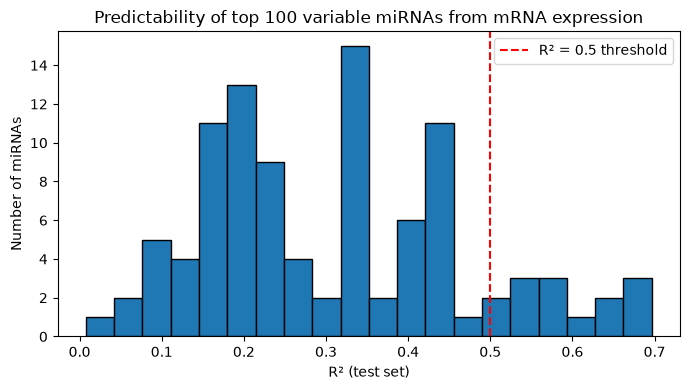

In [24]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(r2_results, bins=20, edgecolor="black")
ax.axvline(0.5, color="red", linestyle="--", label="R² = 0.5 threshold")
ax.set_xlabel("R² (test set)")
ax.set_ylabel("Number of miRNAs")
ax.set_title("Predictability of top 100 variable miRNAs from mRNA expression")
ax.legend()
plt.tight_layout()
plt.savefig("data/r2_distribution.png", dpi=150)
plt.show()

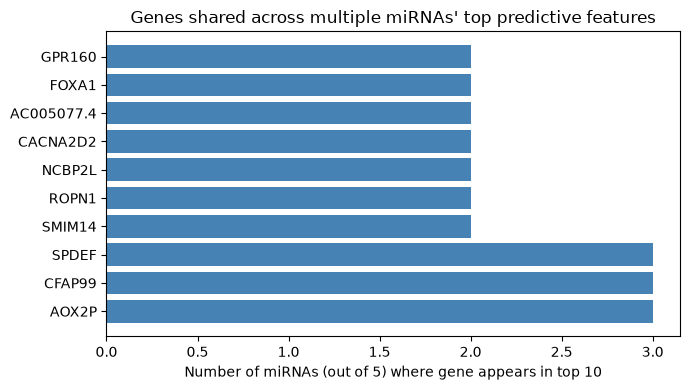

In [25]:
fig, ax = plt.subplots(figsize=(7, 4))
gene_names = [gene_lookup.get(g, g) for g in shared_genes.keys()]
counts = list(shared_genes.values())
order = sorted(range(len(counts)), key=lambda i: -counts[i])

ax.barh([gene_names[i] for i in order], [counts[i] for i in order], color="steelblue")
ax.set_xlabel("Number of miRNAs (out of 5) where gene appears in top 10")
ax.set_title("Genes shared across multiple miRNAs' top predictive features")
plt.tight_layout()
plt.savefig("data/shared_genes.png", dpi=150)
plt.show()

In [27]:
vgll1_id = gene_lookup[gene_lookup == "VGLL1"].index
if len(vgll1_id) > 0:
    print(shap_results["hsa-mir-934"].get(vgll1_id[0], "not in top-ranked features"))

0.010433063249580706


In [28]:
full_ranking = shap_results["hsa-mir-934"].rank(ascending=False)
print("VGLL1 rank:", full_ranking.get(vgll1_id[0]))
print("Total genes ranked:", len(shap_results["hsa-mir-934"]))

VGLL1 rank: 16.0
Total genes ranked: 60660
